# Проект 1. Аналитическая записка

Учебный проект по данным подписки ПРАЙМ.

## Статус

В работе используется персональная когорта из `prime.assignments`: клиенты, которые пользовались ПРАЙМ с планшета в июне 2025 года. Анализ проверяет две согласованные бизнес-гипотезы, использует данные до июля 2026 года включительно и содержит проверки качества данных, зерна и контрольных сумм.

## Бизнес-вопросы

1. **Является ли планшет основным каналом использования ПРАЙМ для клиентов заданной когорты, или после июня их активность преимущественно продолжается на других устройствах?**

2. **За счёт чего выросла выручка от заданной когорты в июле 2026 года по сравнению с июлем 2025 года при одновременном сокращении количества платящих подписок?**

## Методология

### Вопрос 1. Использование устройств

- Когорта фиксируется персональным условием из `prime.assignments`.
- Зерно расчёта — `клиент × месяц × устройство`.
- Период наблюдения — июль 2025 — июль 2026. Июнь 2025 исключён, поскольку по планшетной активности в этом месяце сформирована сама когорта.
- События с `ended_at < started_at` исключаются только из часов, но сохраняются в числе событий.

### Вопрос 2. Изменение выручки

- Зерно расчёта — `подписка × месяц`; шеринг не размножает выручку.
- Сравниваются июль 2025 и июль 2026, а динамика проверяется за все 13 месяцев.
- Выручка — успешные платежи после исключения возможных повторных списаний: та же подписка и сумма в пределах 20 минут.
- Декомпозиция: `выручка = платящие подписки × платежей на подписку × средний успешный платёж`.

## Подключение и параметры анализа

In [1]:
import itertools
import math

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

from prime.config import get_engine

engine = get_engine()


def q(sql: str, **params) -> pd.DataFrame:
    """Выполнить параметризованный SQL-запрос и вернуть DataFrame."""
    try:
        with engine.connect() as connection:
            connection.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), connection, params=params)
    finally:
        engine.dispose()

In [2]:
# Задаём границы один раз: правый конец периода не включается.
USAGE_START = "2025-07-01"
ANALYSIS_END = "2026-08-01"
BASE_MONTH = "2025-07"
REPORT_MONTH = "2026-07"
DUPLICATE_GAP_MINUTES = 20

In [3]:
# Читаем персональное назначение и не выводим SQL-фильтр целиком.
assignment = q(
    '''
    select login, table_name, segment_column, segment,
           period_start, period_end, client_filter
    from prime.assignments
    where login = current_user
    '''
)

assert len(assignment) == 1, 'Ожидалась ровно одна строка персонального задания'
task = assignment.iloc[0]
assignment.drop(columns='client_filter')

,login,table_name,segment_column,segment,period_start,period_end
0,iaefremenkov,service_usage,device_type,tablet,2025-06-01,2025-06-30


In [4]:
# Формируем фиксированную когорту по условию преподавателя.
client_filter = str(task['client_filter']).strip()
cohort_sql = f'''
select distinct client_id
from prime.clients
where {client_filter}
'''

cohort = q(cohort_sql)
print('Когорта сформирована; идентификаторы клиентов не выводятся.')

Когорта сформирована; идентификаторы клиентов не выводятся.


In [5]:
# Проверяем зерно когорты до соединения с таблицами фактов.
cohort_check = pd.DataFrame(
    {
        'значение': [
            len(cohort),
            cohort['client_id'].nunique(),
            int(cohort['client_id'].isna().sum()),
        ]
    },
    index=['строк', 'уникальных клиентов', 'пропущенных client_id'],
)

assert cohort['client_id'].is_unique, 'В когорте появились дубли client_id'
assert cohort['client_id'].notna().all(), 'В когорте есть пропущенные client_id'
cohort_check

,значение
строк,21518
уникальных клиентов,21518
пропущенных client_id,0


## 1. Использование устройств

Сначала проверим качество событий, затем соберём витрину нужного зерна и рассчитаем метрики.

In [6]:
# Считаем дефекты событий и их влияние на длительность без выгрузки сырых строк.
usage_audit = q(f"""
    with cohort as ({cohort_sql})
    select
        count(*) as events,
        count(*) filter (where su.device_type is null) as missing_device,
        count(*) filter (where su.ended_at is null) as missing_end,
        count(*) filter (where su.ended_at < su.started_at) as reversed_sessions,
        count(*) filter (where su.ended_at = su.started_at) as zero_sessions,
        coalesce(sum(extract(epoch from (su.ended_at - su.started_at))) / 3600.0, 0)::double precision as raw_hours,
        coalesce(sum(case when su.ended_at >= su.started_at
                          then extract(epoch from (su.ended_at - su.started_at)) / 3600.0
                          else 0 end), 0)::double precision as clean_hours
    from prime.service_usage su
    join cohort using (client_id)
    where su.started_at >= :start and su.started_at < :end
""", start=USAGE_START, end=ANALYSIS_END)

usage_audit.T.rename(columns={0: "значение"})

,значение
events,755265.000000
missing_device,0.000000
missing_end,0.000000
reversed_sessions,1471.000000
zero_sessions,0.000000
raw_hours,338620.857778
clean_hours,339265.315556


In [7]:
# Показываем масштаб дефектов и сдвиг часов после очистки.
usage_quality = usage_audit.iloc[0]
usage_quality_report = pd.DataFrame({
    "проверка": ["нет устройства", "нет конца", "конец раньше начала", "нулевая длительность"],
    "строк": [usage_quality["missing_device"], usage_quality["missing_end"],
              usage_quality["reversed_sessions"], usage_quality["zero_sessions"]],
})
usage_quality_report["доля_pct"] = 100 * usage_quality_report["строк"] / usage_quality["events"]

print(usage_quality_report.round({"доля_pct": 3}).to_string(index=False))
print()
print(f"часы как есть: {usage_quality['raw_hours']:,.1f}")
print(f"часы без отрицательных интервалов: {usage_quality['clean_hours']:,.1f}")

            проверка  строк  доля_pct
      нет устройства    0.0     0.000
           нет конца    0.0     0.000
 конец раньше начала 1471.0     0.195
нулевая длительность    0.0     0.000

часы как есть: 338,620.9
часы без отрицательных интервалов: 339,265.3


In [8]:
# Собираем витрину клиент × месяц × устройство и сохраняем дефектные события в счётчике.
client_month_device = q(f"""
    with cohort as ({cohort_sql})
    select
        su.client_id,
        date_trunc('month', su.started_at)::date as month,
        coalesce(su.device_type, 'unknown') as device_type,
        count(*) as events,
        sum(case when su.ended_at >= su.started_at
                 then extract(epoch from (su.ended_at - su.started_at)) / 3600.0
                 else 0 end)::double precision as usage_hours
    from prime.service_usage su
    join cohort using (client_id)
    where su.started_at >= :start and su.started_at < :end
    group by su.client_id, date_trunc('month', su.started_at)::date,
             coalesce(su.device_type, 'unknown')
""", start=USAGE_START, end=ANALYSIS_END)

In [9]:
# Проверяем объявленное зерно и число активных клиентов.
usage_grain = ["client_id", "month", "device_type"]
assert not client_month_device.duplicated(usage_grain).any(), "Нарушено зерно витрины"

print(f"строк витрины: {len(client_month_device):,}")
print(f"активных клиентов: {client_month_device['client_id'].nunique():,} из {len(cohort):,}")

строк витрины: 371,720
активных клиентов: 21,037 из 21,518


In [10]:
# Сравниваем устройства по событиям, часам и уникальным активным клиентам.
device_summary = (client_month_device
    .groupby("device_type", as_index=False)
    .agg(events=("events", "sum"), active_clients=("client_id", "nunique"),
         usage_hours=("usage_hours", "sum")))
device_summary["event_share_pct"] = 100 * device_summary["events"] / device_summary["events"].sum()
device_summary["hour_share_pct"] = 100 * device_summary["usage_hours"] / device_summary["usage_hours"].sum()
device_summary["cohort_reach_pct"] = 100 * device_summary["active_clients"] / len(cohort)
device_summary = (device_summary.sort_values("events", ascending=False).reset_index(drop=True)
                  .round({"usage_hours": 1, "event_share_pct": 1,
                          "hour_share_pct": 1, "cohort_reach_pct": 1}))
device_summary

,device_type,events,active_clients,usage_hours,event_share_pct,hour_share_pct,cohort_reach_pct
0,mobile,460577,20766,207403.2,61.0,61.1,96.5
1,desktop,143493,19129,64071.9,19.0,18.9,88.9
2,tv,98162,18110,44115.2,13.0,13.0,84.2
3,tablet,53033,15574,23675.0,7.0,7.0,72.4


In [11]:
# Разворачиваем месяцы в строки, устройства в колонки и проверяем сумму долей.
monthly_device_events = client_month_device.pivot_table(
    index="month", columns="device_type", values="events", aggfunc="sum", fill_value=0)
monthly_device_share = monthly_device_events.div(monthly_device_events.sum(axis=1), axis=0) * 100
assert (monthly_device_share.sum(axis=1).sub(100).abs() < 0.01).all(), "Доли не дают 100%"
monthly_device_share.round(1)

device_type,desktop,mobile,tablet,tv
month,,,,
2025-07-01,19.1,60.9,7.0,12.9
2025-08-01,19.1,61.0,7.0,13.0
2025-09-01,18.8,61.1,7.0,13.1
2025-10-01,19.1,60.9,7.1,12.9
2025-11-01,18.9,61.1,7.0,13.0
2025-12-01,19.0,60.9,7.0,13.1
2026-01-01,18.7,61.2,6.9,13.2
2026-02-01,19.2,60.8,7.1,12.9
2026-03-01,19.0,60.7,7.0,13.3


In [12]:
# Считаем долю активных клиентов месяца, использовавших каждое устройство.
monthly_all = (client_month_device.groupby("month", as_index=False)
               .agg(any_device_clients=("client_id", "nunique"), all_events=("events", "sum")))
monthly_device_clients = client_month_device.pivot_table(
    index="month", columns="device_type", values="client_id", aggfunc="nunique", fill_value=0)
monthly_device_client_share = (monthly_device_clients
    .div(monthly_all.set_index("month")["any_device_clients"], axis=0).mul(100))
monthly_device_client_share.round(1)

device_type,desktop,mobile,tablet,tv
month,,,,
2025-07-01,47.9,86.4,22.9,36.7
2025-08-01,48.0,86.0,23.1,37.1
2025-09-01,47.0,86.1,22.1,36.3
2025-10-01,47.4,86.5,22.7,36.5
2025-11-01,46.8,85.6,22.4,35.8
2025-12-01,47.4,85.7,22.6,37.0
2026-01-01,47.1,86.0,22.6,36.8
2026-02-01,45.6,84.9,21.7,35.1
2026-03-01,47.4,85.4,22.4,37.4


In [13]:
# Сворачиваем активность до клиента × устройство и отдельно проверяем ничьи за первое место.
client_device = (client_month_device.groupby(["client_id", "device_type"], as_index=False)
                 .agg(events=("events", "sum"), usage_hours=("usage_hours", "sum")))
event_ties = (client_device["events"].eq(client_device.groupby("client_id")["events"].transform("max"))
              .groupby(client_device["client_id"]).sum().gt(1).sum())
hour_ties = (client_device["usage_hours"].eq(client_device.groupby("client_id")["usage_hours"].transform("max"))
             .groupby(client_device["client_id"]).sum().gt(1).sum())
print(f"ничьих по событиям: {event_ties:,}")
print(f"ничьих по часам: {hour_ties:,}")

ничьих по событиям: 773
ничьих по часам: 1


In [14]:
# Выбираем основное устройство клиента; при ничьей используем алфавитный порядок.
primary_events = (client_device.sort_values(["client_id", "events", "device_type"],
                  ascending=[True, False, True]).drop_duplicates("client_id")
                  [["client_id", "device_type"]].rename(columns={"device_type": "по событиям"}))
primary_hours = (client_device.sort_values(["client_id", "usage_hours", "device_type"],
                 ascending=[True, False, True]).drop_duplicates("client_id")
                 [["client_id", "device_type"]].rename(columns={"device_type": "по часам"}))
primary_device = (cohort.merge(primary_events, on="client_id", how="left", validate="1:1")
                  .merge(primary_hours, on="client_id", how="left", validate="1:1")
                  .fillna({"по событиям": "нет активности", "по часам": "нет активности"}))
pd.crosstab(primary_device["по событиям"], primary_device["по часам"], margins=True)

по часам,desktop,mobile,tablet,tv,нет активности,All
по событиям,,,,,,
desktop,503,266,39,73,0,881
mobile,671,18603,184,444,0,19902
tablet,3,3,61,5,0,72
tv,16,19,7,140,0,182
нет активности,0,0,0,0,481,481
All,1193,18891,291,662,481,21518


In [15]:
# Показываем распределение основного устройства относительно всей когорты.
primary_device_summary = (primary_device[["по событиям", "по часам"]]
    .melt(var_name="критерий", value_name="устройство")
    .groupby(["критерий", "устройство"], as_index=False).size())
primary_device_summary["доля_когорты_pct"] = 100 * primary_device_summary["size"] / len(cohort)
primary_device_summary.pivot_table(index="устройство", columns="критерий",
                                   values="доля_когорты_pct", fill_value=0).round(1)

критерий,по событиям,по часам
устройство,,
desktop,4.1,5.5
mobile,92.5,87.8
tablet,0.3,1.4
tv,0.8,3.1
нет активности,2.2,2.2


In [16]:
# Считаем, на скольких разных устройствах проявлялся каждый клиент после июня.
device_breadth = (client_device.groupby("client_id")["device_type"].nunique()
                  .rename("devices_used").reindex(cohort["client_id"], fill_value=0))
breadth_summary = device_breadth.value_counts().sort_index().rename_axis("устройств").to_frame("клиентов")
breadth_summary["доля_когорты_pct"] = 100 * breadth_summary["клиентов"] / len(cohort)
breadth_summary.round({"доля_когорты_pct": 1})

,клиентов,доля_когорты_pct
устройств,,
0,481,2.2
1,849,3.9
2,1819,8.5
3,4384,20.4
4,13985,65.0


In [17]:
# Считаем возврат на планшет относительно всей фиксированной когорты.
monthly_all = (
    client_month_device
    .groupby('month', as_index=False)
    .agg(
        any_device_clients=('client_id', 'nunique'),
        all_events=('events', 'sum'),
    )
)

monthly_tablet = (
    client_month_device[client_month_device['device_type'].eq('tablet')]
    .groupby('month', as_index=False)
    .agg(
        tablet_clients=('client_id', 'nunique'),
        tablet_events=('events', 'sum'),
    )
)

tablet_return = monthly_all.merge(monthly_tablet, on='month', how='left').fillna(0)
tablet_return['tablet_return_pct'] = (
    100 * tablet_return['tablet_clients'] / len(cohort)
)
tablet_return['tablet_event_share_pct'] = (
    100 * tablet_return['tablet_events'] / tablet_return['all_events']
)

tablet_return = tablet_return.round(
    {'tablet_return_pct': 1, 'tablet_event_share_pct': 1}
)
tablet_return

,month,any_device_clients,all_events,tablet_clients,tablet_events,tablet_return_pct,tablet_event_share_pct
0,2025-07-01,17065,68043,3914,4792,18.2,7.0
1,2025-08-01,16566,66275,3831,4640,17.8,7.0
2,2025-09-01,16047,62320,3545,4358,16.5,7.0
3,2025-10-01,15834,62874,3596,4448,16.7,7.1
4,2025-11-01,15336,59610,3428,4173,15.9,7.0
5,2025-12-01,15202,60194,3436,4237,16.0,7.0
6,2026-01-01,14886,58944,3357,4088,15.6,6.9
7,2026-02-01,14179,51932,3080,3665,14.3,7.1
8,2026-03-01,14336,56241,3216,3951,14.9,7.0
9,2026-04-01,13793,50397,2900,3437,13.5,6.8


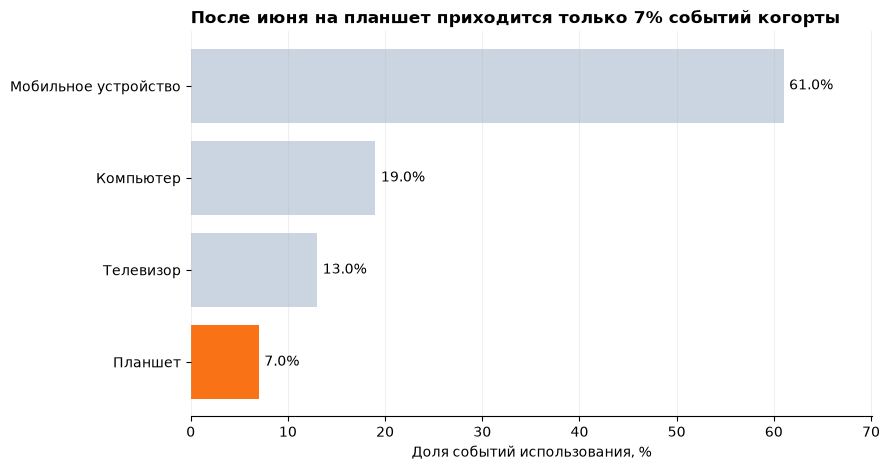

In [18]:
# Показываем суммарную долю событий и выделяем планшет акцентным цветом.
device_labels = {
    'mobile': 'Мобильное устройство',
    'desktop': 'Компьютер',
    'tv': 'Телевизор',
    'tablet': 'Планшет',
}
plot_data = device_summary.sort_values('event_share_pct').copy()
plot_data['device_label'] = plot_data['device_type'].map(device_labels)
colors = [
    '#F97316' if device == 'tablet' else '#CBD5E1'
    for device in plot_data['device_type']
]

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(plot_data['device_label'], plot_data['event_share_pct'], color=colors)
ax.bar_label(bars, labels=[f'{value:.1f}%' for value in plot_data['event_share_pct']], padding=4)
ax.set_title('После июня на планшет приходится только 7% событий когорты', loc='left', weight='bold')
ax.set_xlabel('Доля событий использования, %')
ax.set_ylabel('')
ax.set_xlim(0, plot_data['event_share_pct'].max() * 1.15)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.grid(axis='x', alpha=0.2)
ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

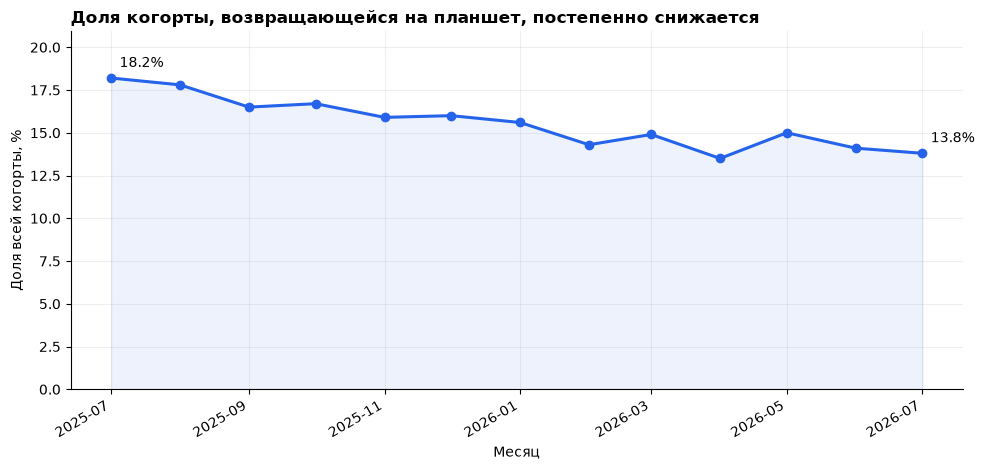

In [19]:
# Показываем помесячную долю когорты, которая снова использовала планшет.
plot_data = tablet_return.copy()
plot_data['month'] = pd.to_datetime(plot_data['month'])

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(
    plot_data['month'],
    plot_data['tablet_return_pct'],
    color='#2563EB',
    marker='o',
    linewidth=2.2,
)
ax.fill_between(
    plot_data['month'],
    plot_data['tablet_return_pct'],
    color='#2563EB',
    alpha=0.08,
)
ax.annotate(
    f"{plot_data.iloc[0]['tablet_return_pct']:.1f}%",
    (plot_data.iloc[0]['month'], plot_data.iloc[0]['tablet_return_pct']),
    xytext=(6, 8),
    textcoords='offset points',
)
ax.annotate(
    f"{plot_data.iloc[-1]['tablet_return_pct']:.1f}%",
    (plot_data.iloc[-1]['month'], plot_data.iloc[-1]['tablet_return_pct']),
    xytext=(6, 8),
    textcoords='offset points',
)
ax.set_title('Доля когорты, возвращающейся на планшет, постепенно снижается', loc='left', weight='bold')
ax.set_xlabel('Месяц')
ax.set_ylabel('Доля всей когорты, %')
ax.set_ylim(0, max(20, plot_data['tablet_return_pct'].max() * 1.15))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.2)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()

### Ответ на первый бизнес-вопрос

**Вывод:** планшет не является основным устройством когорты после июня 2025 года.

**Почему:**

- На планшет приходится только **7% событий и часов использования**.
- Основным устройством по числу событий планшет стал лишь для **0,3% клиентов**, мобильное устройство — для **92,5%**.
- Доля когорты, возвращающейся на планшет, снизилась с **18,2% до 13,8%**.

**Что делать:** развивать переход между планшетом и мобильным устройством — синхронизацию истории, прогресса и рекомендаций. Отдельная стратегия удержания только на планшете затронет слишком небольшую аудиторию.

**Ограничение:** когорта сформирована по планшетной активности в июне 2025 года, поэтому результат нельзя автоматически переносить на всех клиентов ПРАЙМ.

## 2. Изменение выручки

Начинаем с аудита платежей и ловушки шеринга, затем переходим к динамике и декомпозиции.

In [20]:
# Выгружаем платежи когорты за весь период вместе с признаками подписки.
payments = q(f"""
    with cohort as ({cohort_sql})
    select p.payment_id, p.subscription_id, p.paid_at,
           p.amount::double precision as amount, p.status,
           s.tariff_id, s.cancel_reason, s.ended_at
    from prime.payments p
    join prime.subscriptions s using (subscription_id)
    join cohort c on c.client_id = s.owner_client_id
    where p.paid_at >= :start and p.paid_at < :end
    order by p.payment_id
""", start=USAGE_START, end=ANALYSIS_END)
payments["month"] = payments["paid_at"].dt.strftime("%Y-%m")
print(f"платежных попыток: {len(payments):,}")
print(f"подписок: {payments['subscription_id'].nunique():,}")

платежных попыток: 147,955
подписок: 15,618


In [21]:
# Проверяем уникальность ключа, статусы и неположительные успешные суммы.
payment_status = pd.crosstab(payments["month"], payments["status"], margins=True)
nonpositive_success = payments[payments["status"].eq("success") & payments["amount"].le(0)]
assert payments["payment_id"].is_unique, "payment_id должен быть уникальным"
print("неположительных успешных платежей:", len(nonpositive_success))
payment_status

неположительных успешных платежей: 0


status,failed,refunded,success,All
month,,,,
2025-07,391,165,12029,12585
2025-08,441,164,11786,12391
2025-09,388,152,11279,11819
2025-10,398,128,11497,12023
2025-11,391,137,10987,11515
2025-12,394,138,11275,11807
2026-01,365,112,11117,11594
2026-02,323,129,9918,10370
2026-03,390,127,10810,11327


In [22]:
# Проверяем чувствительность числа повторных списаний к порогу времени.
successful_ordered = (payments[payments["status"].eq("success")]
    .sort_values(["subscription_id", "amount", "paid_at", "payment_id"]).copy())
successful_ordered["gap"] = successful_ordered.groupby(["subscription_id", "amount"])["paid_at"].diff()
duplicate_sensitivity = pd.DataFrame({"порог_минут": [1, 2, 5, 10, 20, 60]})
duplicate_sensitivity["строк"] = duplicate_sensitivity["порог_минут"].map(
    lambda minutes: successful_ordered["gap"].lt(pd.Timedelta(minutes=minutes)).sum())
duplicate_sensitivity["сумма_руб"] = duplicate_sensitivity["порог_минут"].map(
    lambda minutes: successful_ordered.loc[
        successful_ordered["gap"].lt(pd.Timedelta(minutes=minutes)), "amount"].sum())
duplicate_sensitivity

,порог_минут,строк,сумма_руб
0,1,3,597.0
1,2,8,1992.0
2,5,38,11112.0
3,10,83,25317.0
4,20,125,36725.0
5,60,125,36725.0


In [23]:
# Исключаем повторные списания по правилу семинара и измеряем влияние очистки.
successful_ordered["possible_duplicate"] = successful_ordered["gap"].lt(
    pd.Timedelta(minutes=DUPLICATE_GAP_MINUTES))
successful = successful_ordered[~successful_ordered["possible_duplicate"]].copy()
duplicate_impact = (successful_ordered.groupby("month")
    .agg(revenue_raw=("amount", "sum"), duplicate_rows=("possible_duplicate", "sum"),
         duplicate_amount=("amount", lambda x: x[
             successful_ordered.loc[x.index, "possible_duplicate"]].sum())))
duplicate_impact["revenue_clean"] = duplicate_impact["revenue_raw"] - duplicate_impact["duplicate_amount"]
duplicate_impact.loc[[BASE_MONTH, REPORT_MONTH]].round(2)

,revenue_raw,duplicate_rows,duplicate_amount,revenue_clean
month,,,,
2025-07,3310571.0,11,3389.0,3307182.0
2026-07,3373570.0,5,1245.0,3372325.0


In [24]:
# Показываем, насколько шеринговое соединение размножило бы каждый успешный платёж.
member_counts = q("""
    select subscription_id, count(*) as shared_members
    from prime.subscription_members
    group by subscription_id
""")
sharing_check = successful.merge(member_counts, on="subscription_id", how="left", validate="m:1")
sharing_check["shared_members"] = sharing_check["shared_members"].fillna(0).astype("int64")
sharing_check["naive_revenue"] = sharing_check["amount"] * (sharing_check["shared_members"] + 1)
sharing_control = pd.DataFrame({
    "расчёт": ["одна подписка — один платёж", "наивное соединение с участниками"],
    "выручка": [sharing_check["amount"].sum(), sharing_check["naive_revenue"].sum()],
})
sharing_control["завышение_pct"] = 100 * (sharing_control["выручка"] / sharing_control.loc[0, "выручка"] - 1)
sharing_control.round({"выручка": 0, "завышение_pct": 1})

,расчёт,выручка,завышение_pct
0,одна подписка — один платёж,41514061.0,0.0
1,наивное соединение с участниками,114540256.0,175.9


In [25]:
# Выносим неизменные признаки подписки в справочник с зерном одна подписка.
subscription_attributes = payments[["subscription_id", "tariff_id", "cancel_reason", "ended_at"]].drop_duplicates()
assert subscription_attributes["subscription_id"].is_unique, "У подписки несколько наборов признаков"
print(f"справочник подписок: {len(subscription_attributes):,} строк")

справочник подписок: 15,618 строк


In [26]:
# Собираем витрину подписка × месяц из очищенных успешных платежей и всех попыток.
attempt_month = (payments.assign(
        failed=lambda d: d["status"].eq("failed"),
        refunded=lambda d: d["status"].eq("refunded"),
        refunded_amount=lambda d: d["amount"].where(d["status"].eq("refunded"), 0))
    .groupby(["subscription_id", "month"], as_index=False)
    .agg(failed_payments=("failed", "sum"), refunded_payments=("refunded", "sum"),
         refunded_amount=("refunded_amount", "sum")))
success_month = (successful.groupby(["subscription_id", "month"], as_index=False)
                 .agg(successful_payments=("payment_id", "size"), revenue=("amount", "sum")))
subscription_month = (attempt_month
    .merge(success_month, on=["subscription_id", "month"], how="left", validate="1:1")
    .merge(subscription_attributes, on="subscription_id", how="left", validate="m:1"))
subscription_month[["successful_payments", "revenue"]] = (
    subscription_month[["successful_payments", "revenue"]].fillna(0))
subscription_month["is_paying"] = subscription_month["successful_payments"].gt(0)

In [27]:
# Проверяем зерно витрины и независимую сумму очищенной выручки.
revenue_grain = ["subscription_id", "month"]
assert not subscription_month.duplicated(revenue_grain).any(), "Нарушено зерно подписка × месяц"
money_gap = subscription_month["revenue"].sum() - successful["amount"].sum()
assert abs(money_gap) < 0.01, "Витрина не сходится с контрольной суммой"
print(f"строк витрины: {len(subscription_month):,}")
print(f"разница с контрольной суммой: {money_gap:.2f} ₽")

строк витрины: 144,705
разница с контрольной суммой: 0.00 ₽


In [28]:
# Считаем помесячную динамику и прирост относительно предыдущего месяца.
monthly_revenue = (subscription_month.groupby("month", as_index=False)
    .agg(paying_subscriptions=("is_paying", "sum"),
         successful_payments=("successful_payments", "sum"), revenue=("revenue", "sum"),
         failed_payments=("failed_payments", "sum"), refunded_payments=("refunded_payments", "sum"),
         refunded_amount=("refunded_amount", "sum")).sort_values("month"))
monthly_revenue["payments_per_subscription"] = (
    monthly_revenue["successful_payments"] / monthly_revenue["paying_subscriptions"])
monthly_revenue["avg_success_payment"] = monthly_revenue["revenue"] / monthly_revenue["successful_payments"]
monthly_revenue["revenue_growth_pct"] = monthly_revenue["revenue"].pct_change() * 100
monthly_revenue.round(2)

,month,paying_subscriptions,successful_payments,revenue,failed_payments,refunded_payments,refunded_amount,payments_per_subscription,avg_success_payment,revenue_growth_pct
0,2025-07,11668,12018.0,3307182.0,391,165,44435.0,1.03,275.19,NaN
1,2025-08,11447,11778.0,3241422.0,441,164,45436.0,1.03,275.21,-1.99
2,2025-09,11210,11271.0,3101729.0,388,152,43248.0,1.01,275.20,-4.31
3,2025-10,11150,11488.0,3167712.0,398,128,34472.0,1.03,275.74,2.13
4,2025-11,10919,10975.0,3021225.0,391,137,37463.0,1.01,275.28,-4.62
5,2025-12,10917,11261.0,3110739.0,394,138,37462.0,1.03,276.24,2.96
6,2026-01,10794,11109.0,3064891.0,365,112,30688.0,1.03,275.89,-1.47
7,2026-02,9908,9908.0,2737292.0,323,129,36671.0,1.00,276.27,-10.69
8,2026-03,10495,10797.0,3513453.0,390,127,40223.0,1.03,325.41,28.36
9,2026-04,9612,9676.0,3157524.0,328,117,37333.0,1.01,326.33,-10.13


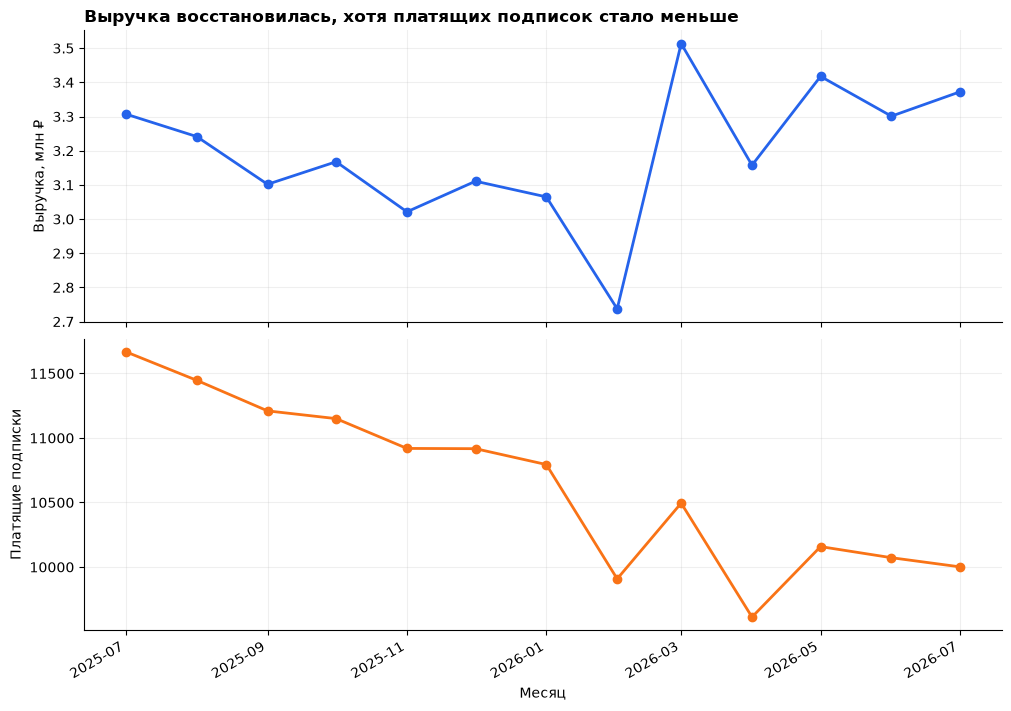

In [29]:
# Показываем, как выручка и платящая база двигались на всём периоде.
plot_data = monthly_revenue.copy()
plot_data["month_date"] = pd.to_datetime(plot_data["month"])
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
axes[0].plot(plot_data["month_date"], plot_data["revenue"] / 1_000_000,
             color="#2563EB", marker="o", linewidth=2)
axes[0].set_title("Выручка восстановилась, хотя платящих подписок стало меньше", loc="left", weight="bold")
axes[0].set_ylabel("Выручка, млн ₽")
axes[1].plot(plot_data["month_date"], plot_data["paying_subscriptions"],
             color="#F97316", marker="o", linewidth=2)
axes[1].set_ylabel("Платящие подписки")
axes[1].set_xlabel("Месяц")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.2)
fig.autofmt_xdate(rotation=30)
plt.show()

In [30]:
# Сравниваем два июля на одинаковом наборе метрик.
july_summary = monthly_revenue.set_index("month").loc[[BASE_MONTH, REPORT_MONTH]]
comparison = july_summary[["paying_subscriptions", "successful_payments",
    "payments_per_subscription", "avg_success_payment", "revenue",
    "failed_payments", "refunded_amount"]].T
comparison["Изменение, %"] = 100 * (comparison[REPORT_MONTH] / comparison[BASE_MONTH] - 1)
comparison.round(2)

month,2025-07,2026-07,"Изменение, %"
paying_subscriptions,11668.00,10001.00,-14.29
successful_payments,12018.00,10325.00,-14.09
payments_per_subscription,1.03,1.03,0.23
avg_success_payment,275.19,326.62,18.69
revenue,3307182.00,3372325.00,1.97
failed_payments,391.00,364.00,-6.91
refunded_amount,44435.00,43819.00,-1.39


In [31]:
# Разделяем платящие подписки на сохранившиеся, потерянные и новые или вернувшиеся.
paying_july = (subscription_month[
    subscription_month["month"].isin([BASE_MONTH, REPORT_MONTH]) & subscription_month["is_paying"]]
    .pivot(index="subscription_id", columns="month", values="is_paying")
    .reindex(columns=[BASE_MONTH, REPORT_MONTH], fill_value=False).fillna(False).astype(bool))
paying_july["движение"] = "сохранились"
paying_july.loc[paying_july[BASE_MONTH] & ~paying_july[REPORT_MONTH], "движение"] = "потеряны"
paying_july.loc[~paying_july[BASE_MONTH] & paying_july[REPORT_MONTH], "движение"] = "новые или вернувшиеся"
payer_movement = paying_july["движение"].value_counts().to_frame("подписок")
assert (payer_movement.loc["новые или вернувшиеся", "подписок"]
        - payer_movement.loc["потеряны", "подписок"]
        == july_summary.loc[REPORT_MONTH, "paying_subscriptions"]
        - july_summary.loc[BASE_MONTH, "paying_subscriptions"]), "Баланс не сошёлся"
payer_movement

,подписок
движение,
сохранились,6984
потеряны,4684
новые или вернувшиеся,3017


In [32]:
# Проверяем, какие потерянные подписки завершились, а какие просто не платили во втором июле.
lost_ids = paying_july.index[paying_july["движение"].eq("потеряны")]
lost_subscriptions = subscription_attributes[subscription_attributes["subscription_id"].isin(lost_ids)].copy()
lost_subscriptions["состояние"] = "нет платежа, но не завершена до августа 2026"
lost_subscriptions.loc[
    lost_subscriptions["ended_at"].notna() & lost_subscriptions["ended_at"].lt(ANALYSIS_END),
    "состояние"] = "завершена до августа 2026"
lost_status_summary = lost_subscriptions["состояние"].value_counts().to_frame("подписок")
lost_status_summary["доля_pct"] = 100 * lost_status_summary["подписок"] / len(lost_subscriptions)
lost_status_summary.round({"доля_pct": 1})

,подписок,доля_pct
состояние,,
завершена до августа 2026,4373,93.4
"нет платежа, но не завершена до августа 2026",311,6.6


In [33]:
# Сравниваем объём, средний платёж и выручку двух тарифов в выбранных месяцах.
tariff_names = {1: "Базовый", 2: "Расширенный"}
tariff_metrics = (successful[successful["month"].isin([BASE_MONTH, REPORT_MONTH])]
    .groupby(["month", "tariff_id"], as_index=False)
    .agg(n_payments=("payment_id", "size"), revenue=("amount", "sum")))
tariff_metrics["avg_payment"] = tariff_metrics["revenue"] / tariff_metrics["n_payments"]
tariff_metrics["payment_share"] = (tariff_metrics["n_payments"]
    / tariff_metrics.groupby("month")["n_payments"].transform("sum"))
tariff_metrics["tariff"] = tariff_metrics["tariff_id"].map(tariff_names)
tariff_metrics.pivot_table(index="tariff", columns="month",
    values=["n_payments", "avg_payment", "payment_share", "revenue"]).round(3)

avg_payment         n_payments         payment_share          \
month           2025-07 2026-07    2025-07 2026-07       2025-07 2026-07   
tariff                                                                     
Базовый           199.0   249.0     7440.0  6318.0         0.619   0.612   
Расширенный       399.0   449.0     4578.0  4007.0         0.381   0.388   

               revenue             
month          2025-07    2026-07  
tariff                             
Базовый      1480560.0  1573182.0  
Расширенный  1826622.0  1799143.0

In [34]:
# Раскладываем рост среднего платежа на структуру тарифов и изменения внутри тарифов.
tariff_indexed = tariff_metrics.set_index(["month", "tariff_id"])
tariff_ids = sorted(tariff_metrics["tariff_id"].unique())
p0 = tariff_indexed.loc[BASE_MONTH, "avg_payment"].reindex(tariff_ids)
p1 = tariff_indexed.loc[REPORT_MONTH, "avg_payment"].reindex(tariff_ids)
w0 = tariff_indexed.loc[BASE_MONTH, "payment_share"].reindex(tariff_ids)
w1 = tariff_indexed.loc[REPORT_MONTH, "payment_share"].reindex(tariff_ids)
mix_effect = ((w1 - w0) * p0).sum()
within_tariff_effect = (w1 * (p1 - p0)).sum()
average_payment_change = (july_summary.loc[REPORT_MONTH, "avg_success_payment"]
                          - july_summary.loc[BASE_MONTH, "avg_success_payment"])
assert abs(mix_effect + within_tariff_effect - average_payment_change) < 0.01, "Разложение не сошлось"
pd.Series({"структура тарифов": mix_effect,
           "средний платёж внутри тарифов": within_tariff_effect,
           "изменение среднего платежа": average_payment_change}).round(2).to_frame("рублей")

,рублей
структура тарифов,1.43
средний платёж внутри тарифов,50.00
изменение среднего платежа,51.43


In [35]:
# Оформляем цепные подстановки функцией и проверяем её на примере с семинара.
def contrib(x0: dict, x1: dict, order: list[str]) -> dict:
    """Менять факторы по одному в заданном порядке и вернуть их вклад."""
    current, effects = dict(x0), {}
    for factor in order:
        before = math.prod(current.values())
        current[factor] = x1[factor]
        effects[factor] = math.prod(current.values()) - before
    total = math.prod(x1.values()) - math.prod(x0.values())
    assert abs(sum(effects.values()) - total) < 0.01, "Сумма влияний не равна изменению"
    return effects

toy = contrib({"ops": 1000, "check": 2000, "rate": 0.015},
              {"ops": 1100, "check": 1800, "rate": 0.016},
              ["ops", "check", "rate"])
assert {key: round(value) for key, value in toy.items()} == {"ops": 3000, "check": -3300, "rate": 1980}
print("проверка функции пройдена")

проверка функции пройдена


In [36]:
# Раскладываем изменение выручки в порядке сколько → как часто → почём.
factor_columns = ["paying_subscriptions", "payments_per_subscription", "avg_success_payment"]
x0 = july_summary.loc[BASE_MONTH, factor_columns].to_dict()
x1 = july_summary.loc[REPORT_MONTH, factor_columns].to_dict()
factor_labels = {"paying_subscriptions": "Количество платящих подписок",
                 "payments_per_subscription": "Платежей на подписку",
                 "avg_success_payment": "Средний успешный платёж"}
effects = pd.Series(contrib(x0, x1, factor_columns)).rename(index=factor_labels)
actual_change = july_summary.loc[REPORT_MONTH, "revenue"] - july_summary.loc[BASE_MONTH, "revenue"]
assert abs(effects.sum() - actual_change) < 0.01, "Декомпозиция не сошлась"
factor_decomposition = effects.rename("вклад_руб").to_frame()
factor_decomposition["доля_изменения_pct"] = 100 * factor_decomposition["вклад_руб"] / actual_change
factor_decomposition.round({"вклад_руб": 0, "доля_изменения_pct": 1})

,вклад_руб,доля_изменения_pct
Количество платящих подписок,-472495.0,-725.3
Платежей на подписку,6606.0,10.1
Средний успешный платёж,531032.0,815.2


In [37]:
# Сравниваем все шесть порядков подстановок и проверяем одинаковую сумму вкладов.
orders = pd.DataFrame({" → ".join(factor_labels[factor] for factor in order):
                       contrib(x0, x1, list(order))
                       for order in itertools.permutations(factor_columns)}).T.rename(columns=factor_labels)
orders["сумма"] = orders.sum(axis=1)
assert orders["сумма"].sub(actual_change).abs().max() < 0.01, "Один из порядков не сошёлся"
orders.round(0).astype(int)

,Количество платящих подписок,Платежей на подписку,Средний успешный платёж,сумма
Количество платящих подписок → Платежей на подписку → Средний успешный платёж,-472495,6606,531032,65143
Количество платящих подписок → Средний успешный платёж → Платежей на подписку,-472495,7840,529798,65143
Платежей на подписку → Количество платящих подписок → Средний успешный платёж,-473596,7707,531032,65143
Платежей на подписку → Средний успешный платёж → Количество платящих подписок,-562110,7707,619547,65143
Средний успешный платёж → Количество платящих подписок → Платежей на подписку,-560804,7840,618106,65143
Средний успешный платёж → Платежей на подписку → Количество платящих подписок,-562110,9147,618106,65143


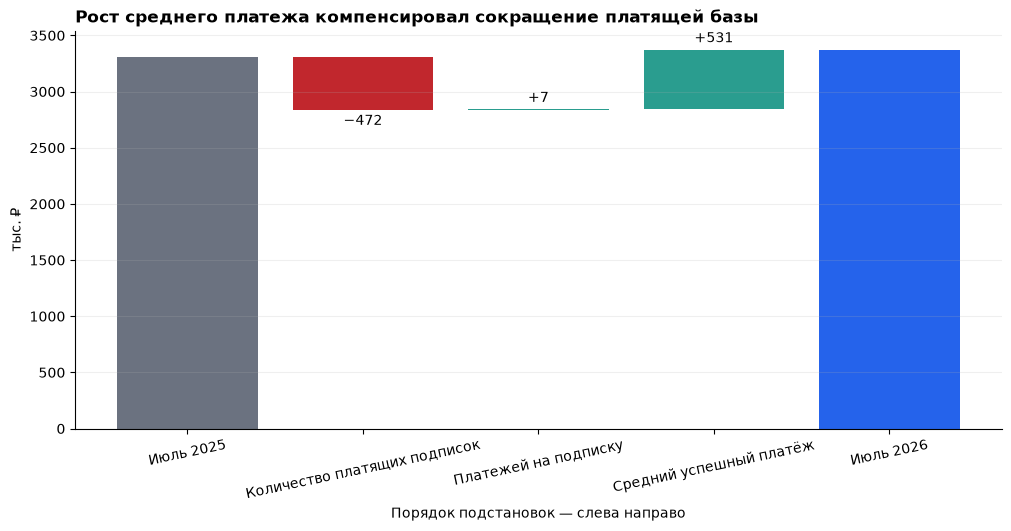

In [38]:
# Строим каскад от базовой выручки к отчётной по вкладам факторов.
start_revenue = july_summary.loc[BASE_MONTH, "revenue"]
end_revenue = july_summary.loc[REPORT_MONTH, "revenue"]
steps = effects / 1000
before = start_revenue / 1000 + steps.cumsum() - steps
colors = ["#C1272D" if value < 0 else "#2A9D8F" for value in steps]
fig, ax = plt.subplots(figsize=(10, 5.2), layout="constrained")
ax.bar("Июль 2025", start_revenue / 1000, color="#6B7280")
bars = ax.bar(steps.index, steps, bottom=before, color=colors)
ax.bar("Июль 2026", end_revenue / 1000, color="#2563EB")
ax.bar_label(bars, fmt=lambda value: f"{value:+,.0f}".replace(",", " ").replace("-", "−"), padding=3)
ax.set_title("Рост среднего платежа компенсировал сокращение платящей базы", loc="left", weight="bold")
ax.set_ylabel("тыс. ₽")
ax.set_xlabel("Порядок подстановок — слева направо")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="x", labelrotation=12)
plt.show()

In [39]:
# Считаем причины только среди потерянных подписок, завершённых до августа 2026.
ended_lost = lost_subscriptions[
    lost_subscriptions["ended_at"].notna() & lost_subscriptions["ended_at"].lt(ANALYSIS_END)].copy()
ended_lost["cancel_reason"] = ended_lost["cancel_reason"].fillna("other")
cancellation_reasons = (ended_lost["cancel_reason"].value_counts()
    .rename_axis("cancel_reason").to_frame("subscriptions"))
cancellation_reasons["share_pct"] = 100 * cancellation_reasons["subscriptions"] / len(ended_lost)
cancellation_reasons.round({"share_pct": 1})

,subscriptions,share_pct
cancel_reason,,
not_using,1481,33.9
too_expensive,1042,23.8
switched,780,17.8
payment_failed,647,14.8
other,423,9.7


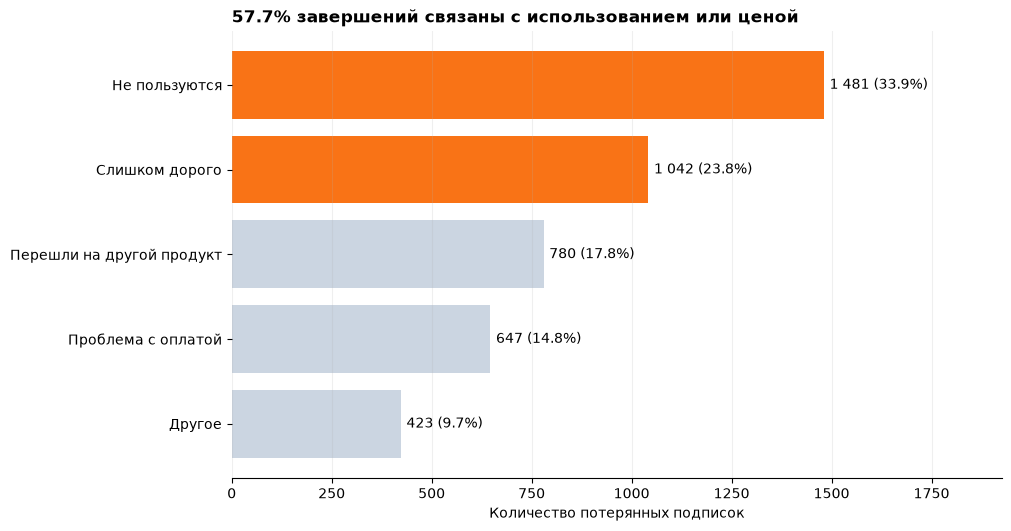

In [40]:
# Показываем основные причины завершения потерянных подписок.
cancel_labels = {"not_using": "Не пользуются", "too_expensive": "Слишком дорого",
                 "switched": "Перешли на другой продукт", "payment_failed": "Проблема с оплатой",
                 "other": "Другое"}
plot_data = cancellation_reasons.reset_index().sort_values("subscriptions").copy()
plot_data["reason_label"] = plot_data["cancel_reason"].map(cancel_labels).fillna(plot_data["cancel_reason"])
colors = ["#F97316" if reason in {"not_using", "too_expensive"} else "#CBD5E1"
          for reason in plot_data["cancel_reason"]]
priority_share = cancellation_reasons.loc[
    cancellation_reasons.index.isin(["not_using", "too_expensive"]), "share_pct"].sum()
fig, ax = plt.subplots(figsize=(10, 5.2), layout="constrained")
bars = ax.barh(plot_data["reason_label"], plot_data["subscriptions"], color=colors)
labels = [f"{count:,} ({share:.1f}%)".replace(",", " ")
          for count, share in zip(plot_data["subscriptions"], plot_data["share_pct"])]
ax.bar_label(bars, labels=labels, padding=4)
ax.set_title(f"{priority_share:.1f}% завершений связаны с использованием или ценой", loc="left", weight="bold")
ax.set_xlabel("Количество потерянных подписок")
ax.set_ylabel("")
ax.set_xlim(0, plot_data["subscriptions"].max() * 1.3)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)
plt.show()

### Ответ на второй бизнес-вопрос

**Вывод:** выручка выросла на **65 тыс. ₽, или 2,0%**, несмотря на сокращение количества платящих подписок на **14,3%**.

**Факторная декомпозиция изменения выручки:**

- сокращение количества платящих подписок: **−472 тыс. ₽**;
- изменение частоты платежей: **+7 тыс. ₽**;
- рост среднего успешного платежа: **+531 тыс. ₽**;
- итоговое изменение выручки: **+65 тыс. ₽**.

Следовательно, выручка выросла **за счёт увеличения среднего платежа**. Этот фактор полностью перекрыл отрицательный эффект от сокращения платящей базы.

**За счёт чего вырос средний платёж:**

- изменение платежа внутри тарифов: **+50,00 ₽**;
- изменение структуры тарифов: **+1,43 ₽**;
- общее изменение среднего платежа: **+51,43 ₽**.

Таким образом, средний платёж вырос преимущественно из-за увеличения платежа внутри каждого тарифа, а не из-за перехода клиентов на более дорогой тариф.

**Что делать:**

- не рассчитывать на дальнейшее повышение цены: платящая база уже сокращается;
- для причины `not_using` усилить реактивацию и демонстрацию полезных сценариев подписки;
- для причины `too_expensive` проверить на пилоте удерживающее предложение или более выгодный способ оплаты;
- вместе с выручкой регулярно контролировать количество платящих подписок и долю продлений, поскольку рост выручки сейчас маскирует сокращение базы.